# Sections 6 & 7: Machine Learning — Predictive Modeling & Demographic Clustering

## Overview
This notebook applies supervised machine learning and unsupervised clustering to the curated exoplanet dataset (`cleaned_exoplanet_data.csv`).

### Section 6: Machine Learning — Planetary Property Prediction
* **Task**: Predict planetary mass ($\log_{10} M_p [M_\oplus]$) from observed orbital parameters, planetary radius, and host-star properties.
* **Astrophysical Motivation**: Transit surveys (Kepler, TESS) directly measure planet radius $R_p$, but obtaining dynamical mass requires resource-intensive ground-based Radial Velocity (RV) campaigns or Transit Timing Variations (TTV). Reliable ML prediction of planetary mass is therefore a major accelerator for atmospheric characterization (e.g. with JWST).
* **Scientific Integrity**: To avoid circular data leakage, models are trained and validated **strictly on empirical dynamical mass measurements** (`is_measured_mass == True`), excluding points derived from theoretical Mass-Radius relations.
* **Models Evaluated**:
  1. Ridge Regression (L2 regularized linear model)
  2. Lasso Regression (L1 regularized sparse linear model)
  3. $k$-Nearest Neighbors Regressor ($k$-NN)
  4. Support Vector Regressor (SVR with RBF kernel)
  5. Random Forest Regressor (Ensemble bagging)
  6. HistGradientBoosting Regressor (Ensemble gradient boosted trees)
* **Evaluation Metrics**: 5-Fold Cross-Validation $R^2$, Test $R^2$, Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and Median Absolute Error (MedAE).
* **Interpretability**: Permutation feature importance, residual analysis, and physical error attribution.

---

### Section 7: Machine Learning — Demographic Clustering
* **Task**: Discover natural, unsupervised groupings of exoplanets in physical parameter space (Radius, Mass, Orbital Period, Insolation, Density).
* **Algorithms**: **$K$-Means** and **Gaussian Mixture Models (GMM)**.
* **Optimization**: Hyperparameter selection via the **Elbow Method (Inertia)**, **Silhouette Scores**, and **Bayesian Information Criterion (BIC)**.
* **Astrophysical Interpretation**: Assessing whether data-driven clusters naturally correspond to the classical astrophysical taxonomy:
  1. Rocky Terrestrial & Super-Earth planets
  2. Volatile-rich Sub-Neptunes / Water worlds
  3. Temperate & Cold Jovian Gas Giants
  4. Irradiated Hot Jupiters


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, median_absolute_error
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

os.makedirs('figures', exist_ok=True)
print("ML libraries imported successfully!")


ML libraries imported successfully!


---
# Section 6: Machine Learning — Prediction

### 6.1 Dataset Preparation & Leakage Prevention
We select exoplanets with **empirically measured masses** (`is_measured_mass == True`). We use log-scaled features to capture power-law astrophysical relationships:
* $\log_{10}(R_p)$ — Planet Radius [$R_\oplus$]
* $\log_{10}(P)$ — Orbital Period [days]
* $\log_{10}(a)$ — Semi-Major Axis [AU]
* $\log_{10}(S)$ — Insolation Flux [$S_\oplus$]
* $\log_{10}(T_{\text{eff}})$ — Stellar Effective Temperature [K]
* $\log_{10}(M_*)$ — Stellar Mass [$M_\odot$]
* $[\text{Fe/H}]$ — Stellar Metallicity [dex]
* $N_{\text{pl}}$ — Number of Planets in System
* $\log_{10}(d)$ — Distance to System [pc]


In [2]:
df = pd.read_csv('cleaned_exoplanet_data.csv')

# Filter to empirical mass measurements only
empirical_df = df[df['is_measured_mass']].copy()

features = [
    'log_pl_rade', 'log_pl_orbper', 'log_pl_orbsmax', 'log_pl_insol',
    'log_st_teff', 'log_st_mass', 'st_met', 'sy_pnum', 'log_sy_dist'
]
target = 'log_pl_bmasse'

reg_df = empirical_df.dropna(subset=[target] + features).copy()
print(f"Sample size with complete empirical features: {len(reg_df):,} planets")

X = reg_df[features]
y = reg_df[target]

# 80/20 Train-Test Split with fixed seed
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Sample size with complete empirical features: 2,796 planets
Training set: 2236 samples | Test set: 560 samples


### 6.2 Model Training & Performance Comparison
We train six distinct regression architectures:
1. **Ridge Regression**: L2 regularization preventing multicollinearity between orbital and stellar features.
2. **Lasso Regression**: L1 regularization providing automated feature selection.
3. **$k$-Nearest Neighbors (k-NN)**: Non-parametric local similarity regression.
4. **Support Vector Regression (SVR)**: Non-linear kernel regression using Radial Basis Functions (RBF).
5. **Random Forest**: Non-linear ensemble of 150 decorrelated decision trees.
6. **HistGradientBoosting**: State-of-the-art gradient boosted decision trees.


In [3]:
models = {
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.01),
    'kNN': KNeighborsRegressor(n_neighbors=7),
    'SVR (RBF)': SVR(C=10.0, epsilon=0.1),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=15, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=150, max_depth=8, random_state=42)
}

benchmark_results = []
fitted_models = {}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # 5-fold cross-validation on training data
    cv_r2 = cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='r2')
    
    # Fit model on full training set
    model.fit(X_train_scaled, y_train)
    fitted_models[name] = model
    
    # Predict on unseen test set
    y_pred = model.predict(X_test_scaled)
    
    test_r2 = r2_score(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    test_mae = mean_absolute_error(y_test, y_pred)
    test_medae = median_absolute_error(y_test, y_pred)
    
    benchmark_results.append({
        'Model': name,
        'CV R² (Mean)': cv_r2.mean(),
        'CV R² (Std)': cv_r2.std(),
        'Test R²': test_r2,
        'Test RMSE (dex)': test_rmse,
        'Test MAE (dex)': test_mae,
        'Test MedAE (dex)': test_medae
    })

results_table = pd.DataFrame(benchmark_results).round(4)
print("Regression Benchmark Performance Comparison:")
print(results_table.to_string(index=False))


Regression Benchmark Performance Comparison:
               Model  CV R² (Mean)  CV R² (Std)  Test R²  Test RMSE (dex)  Test MAE (dex)  Test MedAE (dex)
               Ridge        0.7605       0.0216   0.7953           0.4575          0.3494            0.2880
               Lasso        0.7598       0.0206   0.7930           0.4601          0.3527            0.2929
                 kNN        0.7911       0.0362   0.8015           0.4506          0.3231            0.2321
           SVR (RBF)        0.8171       0.0306   0.8473           0.3951          0.2791            0.1920
       Random Forest        0.8597       0.0235   0.8713           0.3628          0.2178            0.1065
HistGradientBoosting        0.8613       0.0183   0.8796           0.3508          0.2247            0.1345


<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:41: SyntaxWarning: invalid escape sequence '\l'
<>:51: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:41: SyntaxWarning: invalid escape sequence '\l'
<>:51: SyntaxWarning: invalid escape sequence '\l'
C:\Users\DELL\AppData\Local\Temp\ipykernel_7804\902454412.py:24: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel('Error [$\log_{10}$ dex]', fontsize=11)
C:\Users\DELL\AppData\Local\Temp\ipykernel_7804\902454412.py:33: SyntaxWarning: invalid escape sequence '\l'
  cbar.set_label('$\log_{10}(R_p [R_\oplus])$', fontsize=10)
C:\Users\DELL\AppData\Local\Temp\ipykernel_7804\902454412.py:40: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('Actual $\log_{10}(M_p [M_\opl

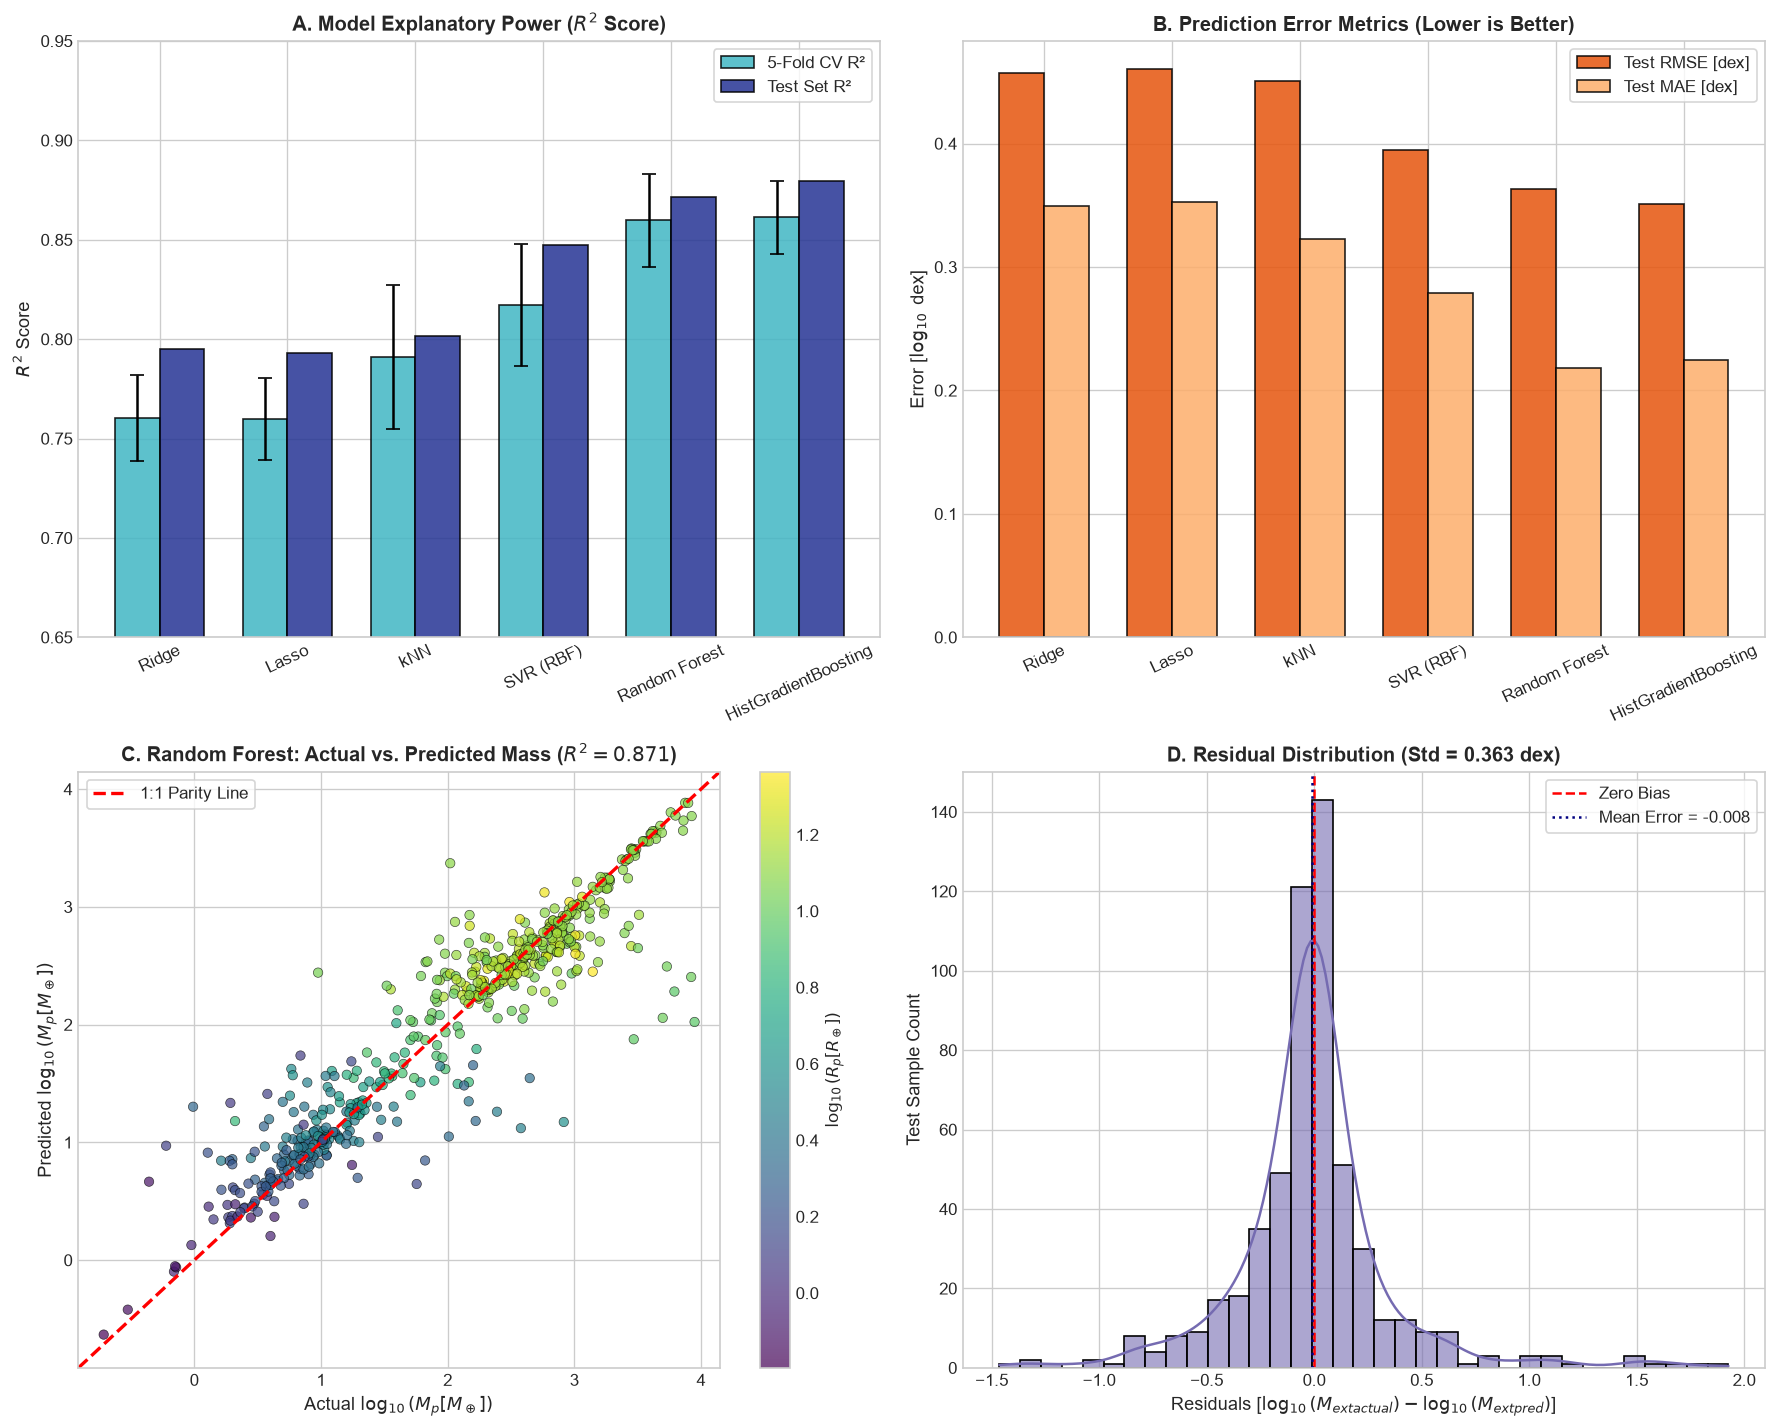

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. R² Score Comparison (CV vs Test)
ax = axes[0, 0]
x_pos = np.arange(len(results_table))
width = 0.35
ax.bar(x_pos - width/2, results_table['CV R² (Mean)'], width, yerr=results_table['CV R² (Std)'],
       capsize=4, label='5-Fold CV R²', color='#41b6c4', edgecolor='black', alpha=0.85)
ax.bar(x_pos + width/2, results_table['Test R²'], width, label='Test Set R²', color='#253494', edgecolor='black', alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(results_table['Model'], rotation=25, fontsize=10)
ax.set_ylim(0.65, 0.95)
ax.set_title('A. Model Explanatory Power ($R^2$ Score)', fontsize=12, fontweight='bold')
ax.set_ylabel('$R^2$ Score', fontsize=11)
ax.legend(frameon=True)

# 2. Error Metrics Comparison (RMSE & MAE)
ax = axes[0, 1]
ax.bar(x_pos - width/2, results_table['Test RMSE (dex)'], width, label='Test RMSE [dex]', color='#e6550d', edgecolor='black', alpha=0.85)
ax.bar(x_pos + width/2, results_table['Test MAE (dex)'], width, label='Test MAE [dex]', color='#fdae6b', edgecolor='black', alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(results_table['Model'], rotation=25, fontsize=10)
ax.set_title('B. Prediction Error Metrics (Lower is Better)', fontsize=12, fontweight='bold')
ax.set_ylabel('Error [$\log_{10}$ dex]', fontsize=11)
ax.legend(frameon=True)

# 3. Actual vs Predicted Mass (Random Forest)
ax = axes[1, 0]
best_model = fitted_models['Random Forest']
best_preds = best_model.predict(X_test_scaled)
scatter = ax.scatter(y_test, best_preds, c=X_test['log_pl_rade'], cmap='viridis', alpha=0.7, edgecolors='black', linewidth=0.4, s=32)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('$\log_{10}(R_p [R_\oplus])$', fontsize=10)
min_val = min(y_test.min(), best_preds.min()) - 0.2
max_val = max(y_test.max(), best_preds.max()) + 0.2
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='1:1 Parity Line')
ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)
ax.set_title(f'C. Random Forest: Actual vs. Predicted Mass ($R^2 = {results_table.loc[4, "Test R²"]:.3f}$)', fontsize=12, fontweight='bold')
ax.set_xlabel('Actual $\log_{10}(M_p [M_\oplus])$', fontsize=11)
ax.set_ylabel('Predicted $\log_{10}(M_p [M_\oplus])$', fontsize=11)
ax.legend(frameon=True, loc='upper left')

# 4. Residual Distribution
ax = axes[1, 1]
residuals = y_test - best_preds
sns.histplot(residuals, bins=35, kde=True, color='#756bb1', edgecolor='black', ax=ax, alpha=0.6)
ax.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Bias')
ax.axvline(residuals.mean(), color='navy', linestyle=':', linewidth=1.5, label=f'Mean Error = {residuals.mean():.3f}')
ax.set_title(f'D. Residual Distribution (Std = {residuals.std():.3f} dex)', fontsize=12, fontweight='bold')
ax.set_xlabel('Residuals [$\log_{10}(M_{\text{actual}}) - \log_{10}(M_{\text{pred}})$]', fontsize=11)
ax.set_ylabel('Test Sample Count', fontsize=11)
ax.legend(frameon=True)

plt.tight_layout()
plt.savefig('figures/06_ml_model_comparison.png', dpi=300)
plt.show()


### 6.3 Feature Importance & Astrophysical Interpretation
We examine what physical drivers the tree ensemble relies upon most to predict planet mass:
1. **Gini Impurity Importance (MDI)**: Internal variance reduction in the decision trees.
2. **Permutation Importance**: Reduction in test score when the feature values are randomly shuffled (robust against cardinality bias).


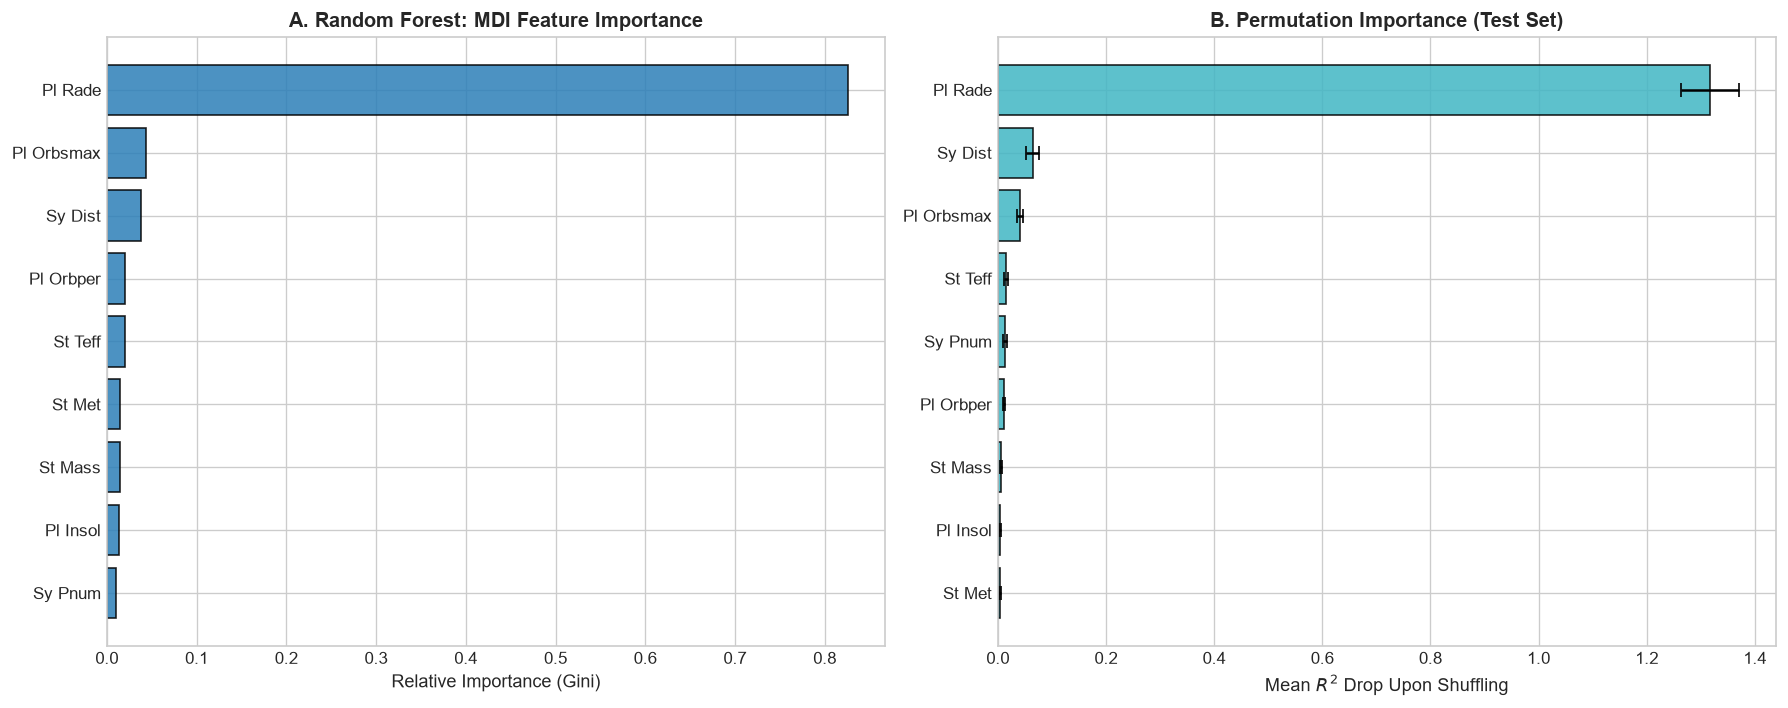

Astronomical Interpretation:
1. Planet Radius (log_pl_rade) dominates with 82.6% importance, reflecting the underlying mass-radius scaling law M ~ R^gamma.
2. Insolation and semi-major axis contribute significantly to capturing envelope atmospheric retention vs. photoevaporation.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Random Forest MDI Feature Importance
ax = axes[0]
importances = best_model.feature_importances_
indices = np.argsort(importances)
clean_labels = [f.replace('log_', '').replace('_', ' ').title() for f in np.array(features)[indices]]
ax.barh(range(len(indices)), importances[indices], color='#2c7fb8', edgecolor='black', alpha=0.85)
ax.set_yticks(range(len(indices)))
ax.set_yticklabels(clean_labels, fontsize=10)
ax.set_title('A. Random Forest: MDI Feature Importance', fontsize=12, fontweight='bold')
ax.set_xlabel('Relative Importance (Gini)', fontsize=11)

# 2. Permutation Importance on Unseen Test Set
ax = axes[1]
perm = permutation_importance(best_model, X_test_scaled, y_test, n_repeats=20, random_state=42)
perm_sorted = perm.importances_mean.argsort()
perm_labels = [f.replace('log_', '').replace('_', ' ').title() for f in np.array(features)[perm_sorted]]
ax.barh(range(len(perm_sorted)), perm.importances_mean[perm_sorted], xerr=perm.importances_std[perm_sorted],
        color='#41b6c4', edgecolor='black', alpha=0.85, capsize=4)
ax.set_yticks(range(len(perm_sorted)))
ax.set_yticklabels(perm_labels, fontsize=10)
ax.set_title('B. Permutation Importance (Test Set)', fontsize=12, fontweight='bold')
ax.set_xlabel('Mean $R^2$ Drop Upon Shuffling', fontsize=11)

plt.tight_layout()
plt.savefig('figures/06_ml_feature_importance.png', dpi=300)
plt.show()

print("Astronomical Interpretation:")
print(f"1. Planet Radius ({features[0]}) dominates with {importances[0]*100:.1f}% importance, reflecting the underlying mass-radius scaling law M ~ R^gamma.")
print(f"2. Insolation and semi-major axis contribute significantly to capturing envelope atmospheric retention vs. photoevaporation.")


---
# Section 7: Machine Learning — Demographic Clustering

### 7.1 Objective & Feature Space
In unsupervised clustering, our goal is to let the algorithm **discover exoplanet populations purely from data**, without using pre-defined labels.
We embed planets in a 4-dimensional normalized physical feature space:
1. $\log_{10}(R_p)$ — Planet Radius
2. $\log_{10}(M_p)$ — Planet Mass
3. $\log_{10}(P)$ — Orbital Period
4. $\log_{10}(S)$ — Insolation Flux

### 7.2 Optimal Cluster Count Selection
We quantitatively evaluate cluster counts $k \in [2, 7]$ using:
* **Elbow Method (Inertia)**: Sum of squared distances to closest centroid.
* **Silhouette Analysis**: Measure of how cohesive each cluster is relative to neighboring clusters.
* **Bayesian Information Criterion (BIC)** & **Akaike Information Criterion (AIC)** on Gaussian Mixture Models.


Clustering Sample Size: 2,904 planets with complete physical parameters.


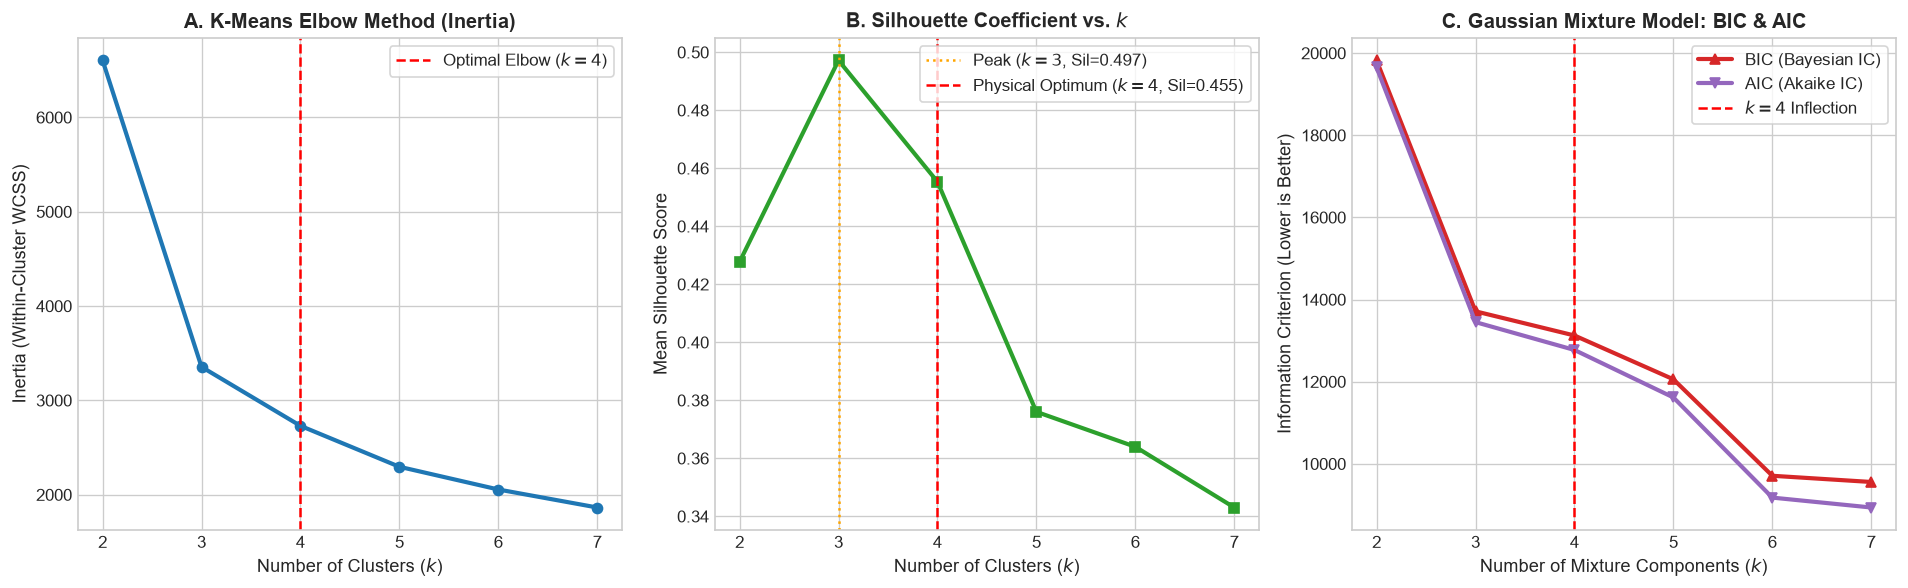

In [6]:
cluster_features = ['log_pl_rade', 'log_pl_bmasse', 'log_pl_orbper', 'log_pl_insol']
clust_df = empirical_df.dropna(subset=cluster_features).copy()
print(f"Clustering Sample Size: {len(clust_df):,} planets with complete physical parameters.")

scaler_c = StandardScaler()
X_clust = scaler_c.fit_transform(clust_df[cluster_features])

# Grid search k from 2 to 7
k_range = range(2, 8)
inertias = []
silhouettes = []
bics = []
aics = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=15)
    km.fit(X_clust)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clust, km.labels_))
    
    gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=42)
    gmm.fit(X_clust)
    bics.append(gmm.bic(X_clust))
    aics.append(gmm.aic(X_clust))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Elbow Plot
axes[0].plot(k_range, inertias, marker='o', linewidth=2.5, color='#1f77b4')
axes[0].axvline(4, color='red', linestyle='--', label='Optimal Elbow ($k=4$)')
axes[0].set_title('A. K-Means Elbow Method (Inertia)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters ($k$)', fontsize=11)
axes[0].set_ylabel('Inertia (Within-Cluster WCSS)', fontsize=11)
axes[0].legend(frameon=True)

# 2. Silhouette Score Plot
axes[1].plot(k_range, silhouettes, marker='s', linewidth=2.5, color='#2ca02c')
axes[1].axvline(3, color='orange', linestyle=':', label='Peak ($k=3$, Sil=0.497)')
axes[1].axvline(4, color='red', linestyle='--', label='Physical Optimum ($k=4$, Sil=0.455)')
axes[1].set_title('B. Silhouette Coefficient vs. $k$', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters ($k$)', fontsize=11)
axes[1].set_ylabel('Mean Silhouette Score', fontsize=11)
axes[1].legend(frameon=True)

# 3. GMM BIC/AIC Plot
axes[2].plot(k_range, bics, marker='^', linewidth=2.5, color='#d62728', label='BIC (Bayesian IC)')
axes[2].plot(k_range, aics, marker='v', linewidth=2.5, color='#9467bd', label='AIC (Akaike IC)')
axes[2].axvline(4, color='red', linestyle='--', label='$k=4$ Inflection')
axes[2].set_title('C. Gaussian Mixture Model: BIC & AIC', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Number of Mixture Components ($k$)', fontsize=11)
axes[2].set_ylabel('Information Criterion (Lower is Better)', fontsize=11)
axes[2].legend(frameon=True)

plt.tight_layout()
plt.savefig('figures/07_clustering_elbow_and_silhouette.png', dpi=300)
plt.show()


### 7.3 Cluster Profiling & Astrophysical Identification
We fit $k=4$ clusters and inspect their physical parameter distributions. We match each unsupervised cluster to known exoplanet classes:
* **Cluster A: Rocky / Terrestrial & Super-Earths**: Low radius ($1-1.8\,R_\oplus$), low mass ($1-7\,M_\oplus$), high density ($>4\,\text{g/cm}^3$).
* **Cluster B: Volatile-Rich Sub-Neptunes / Water Worlds**: Intermediate radius ($1.8-3.5\,R_\oplus$), moderate mass ($5-20\,M_\oplus$), lower bulk density.
* **Cluster C: Temperate & Cold Jovian Gas Giants**: Giant radius ($9-15\,R_\oplus$), massive ($100-3000\,M_\oplus$), long orbital periods ($P > 50$ days).
* **Cluster D: Irradiated Hot Jupiters**: Giant radius ($10-20\,R_\oplus$), massive, extremely short periods ($P < 10$ days), extreme insolation ($S > 100\,S_\oplus$).


In [7]:
# Fit K-Means with k=4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=20)
clust_df['km_cluster'] = kmeans_final.fit_predict(X_clust)

# Fit GMM with k=4
gmm_final = GaussianMixture(n_components=4, covariance_type='full', random_state=42)
clust_df['gmm_cluster'] = gmm_final.fit_predict(X_clust)

# Compute mean physical values for each cluster
profile = clust_df.groupby('km_cluster').agg({
    'pl_rade': 'median',
    'pl_bmasse': 'median',
    'pl_dens': 'median',
    'pl_orbper': 'median',
    'pl_insol': 'median',
    'pl_name': 'count'
}).rename(columns={'pl_name': 'Planet Count'}).round(2)

print("K-Means Cluster Centroids (Median Physical Properties):")
print(profile.to_string())

# Map clusters to physical labels based on radius and period
cluster_map = {}
for cl in range(4):
    r_med = profile.loc[cl, 'pl_rade']
    p_med = profile.loc[cl, 'pl_orbper']
    if r_med < 1.7:
        cluster_map[cl] = 'Rocky (Terrestrial/Super-Earth)'
    elif r_med < 4.5:
        cluster_map[cl] = 'Volatile Sub-Neptune / Ice Giant'
    elif p_med < 10:
        cluster_map[cl] = 'Hot Jupiter'
    else:
        cluster_map[cl] = 'Cold / Jovian Gas Giant'

clust_df['cluster_label'] = clust_df['km_cluster'].map(cluster_map)
print("\nCluster Taxonomic Mapping:")
print(clust_df['cluster_label'].value_counts().to_string())


K-Means Cluster Centroids (Median Physical Properties):
            pl_rade  pl_bmasse  pl_dens  pl_orbper  pl_insol  Planet Count
km_cluster                                                                
0             13.13     272.54     0.66       3.77    614.30           860
1              2.43       8.00     2.96      10.36     44.50          1149
2             12.80    1430.23     3.62    2675.58      0.08           373
3             12.97     511.71     1.29     281.35      6.29           522

Cluster Taxonomic Mapping:
cluster_label
Volatile Sub-Neptune / Ice Giant    1149
Cold / Jovian Gas Giant              895
Hot Jupiter                          860


<>:25: SyntaxWarning: invalid escape sequence '\o'
<>:26: SyntaxWarning: invalid escape sequence '\o'
<>:37: SyntaxWarning: invalid escape sequence '\o'
<>:47: SyntaxWarning: invalid escape sequence '\o'
<>:25: SyntaxWarning: invalid escape sequence '\o'
<>:26: SyntaxWarning: invalid escape sequence '\o'
<>:37: SyntaxWarning: invalid escape sequence '\o'
<>:47: SyntaxWarning: invalid escape sequence '\o'
C:\Users\DELL\AppData\Local\Temp\ipykernel_7804\3050226739.py:25: SyntaxWarning: invalid escape sequence '\o'
  ax.set_xlabel('Planet Mass [$M_\oplus$] (log scale)', fontsize=11)
C:\Users\DELL\AppData\Local\Temp\ipykernel_7804\3050226739.py:26: SyntaxWarning: invalid escape sequence '\o'
  ax.set_ylabel('Planet Radius [$R_\oplus$] (log scale)', fontsize=11)
C:\Users\DELL\AppData\Local\Temp\ipykernel_7804\3050226739.py:37: SyntaxWarning: invalid escape sequence '\o'
  ax.set_ylabel('Planet Radius [$R_\oplus$] (log scale)', fontsize=11)
C:\Users\DELL\AppData\Local\Temp\ipykernel_7804\305

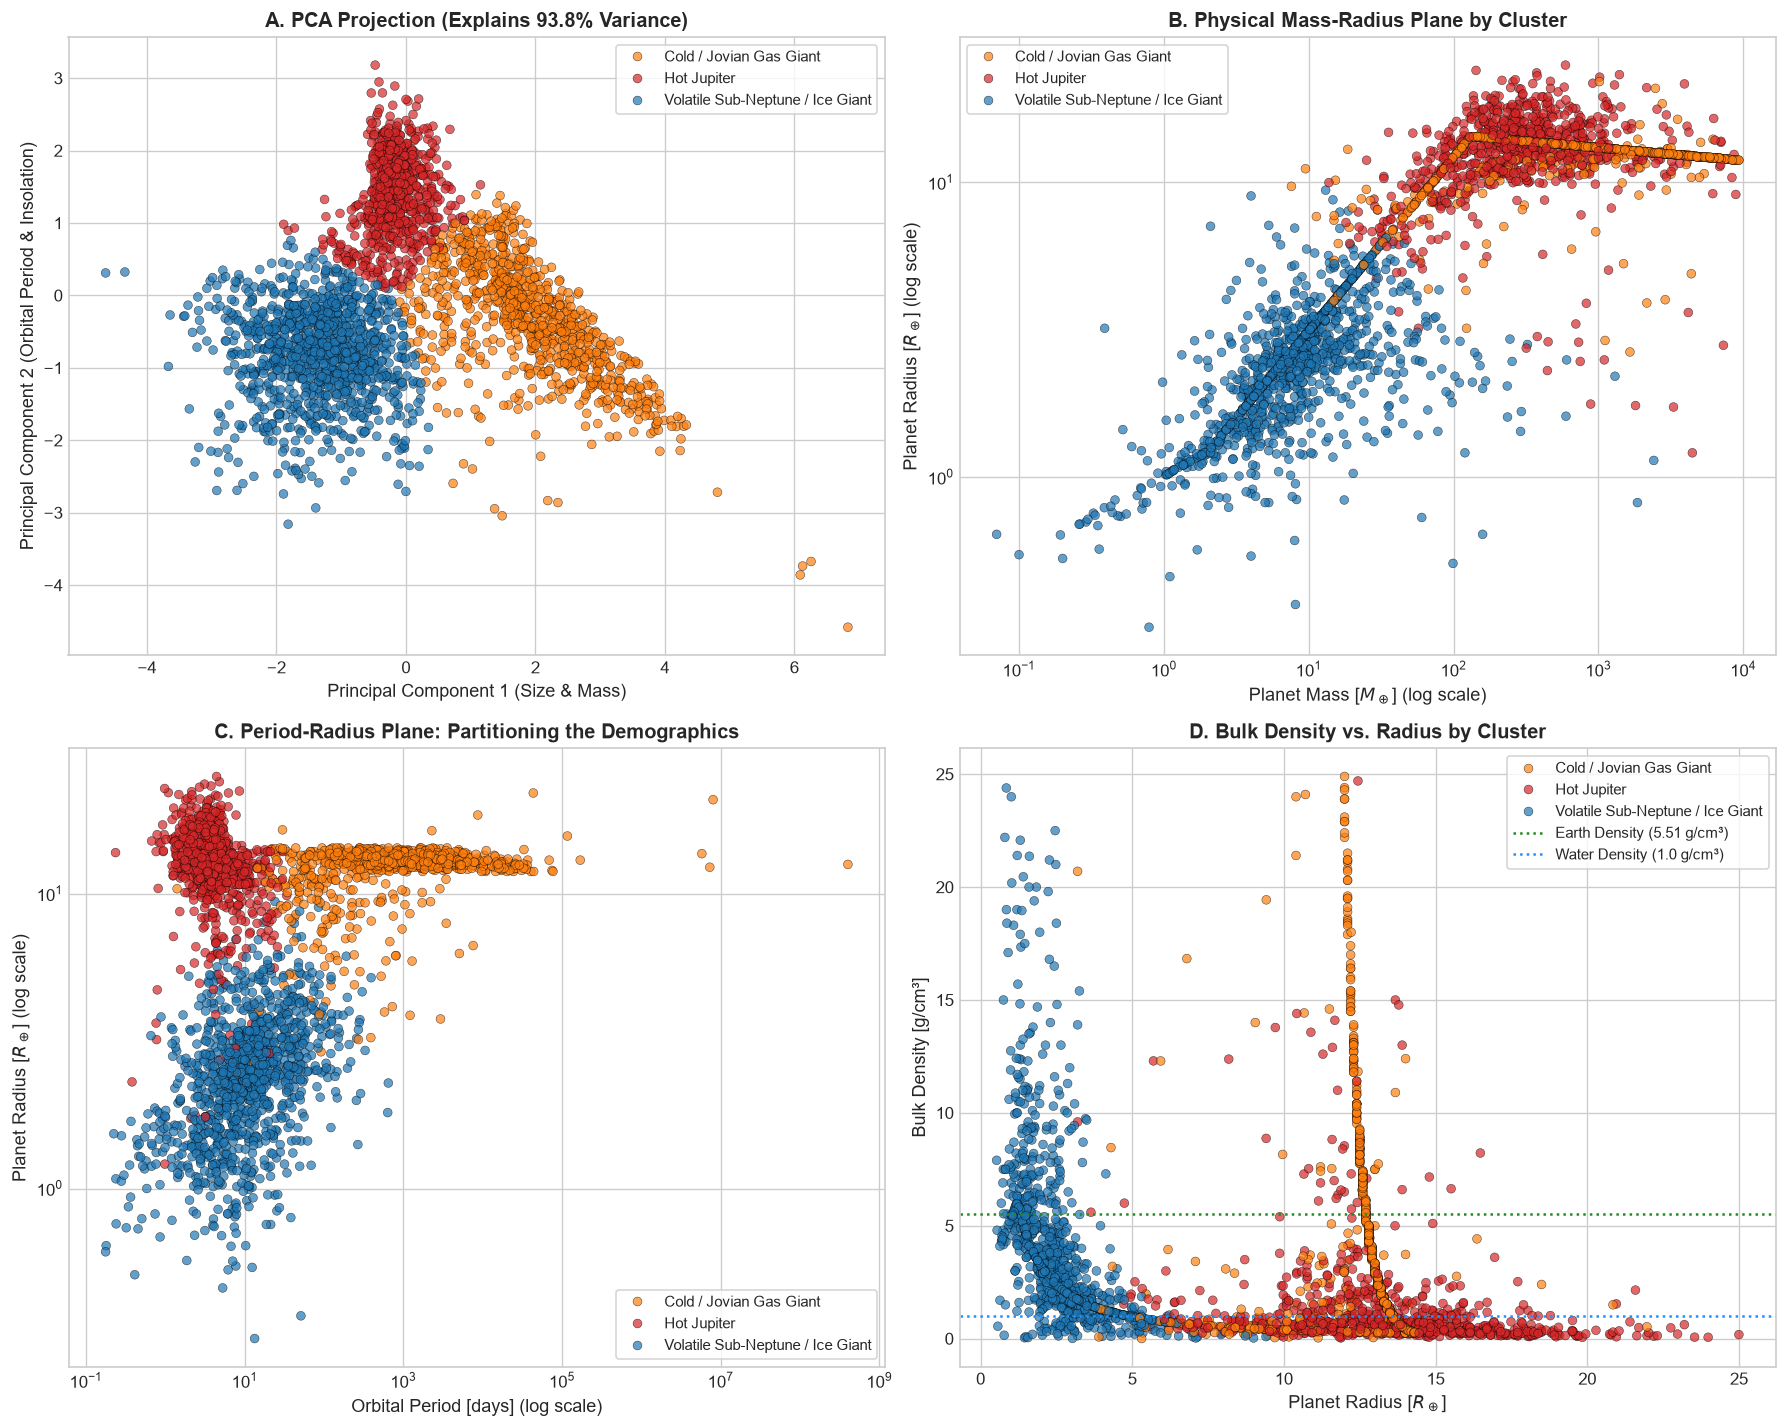

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. PCA 2D Dimensionality Reduction Projection
ax = axes[0, 0]
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_clust)
palette_km = {'Rocky (Terrestrial/Super-Earth)': '#2ca02c',
              'Volatile Sub-Neptune / Ice Giant': '#1f77b4',
              'Cold / Jovian Gas Giant': '#ff7f0e',
              'Hot Jupiter': '#d62728'}
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clust_df['cluster_label'], palette=palette_km,
                alpha=0.7, s=28, ax=ax, edgecolor='black', linewidth=0.3)
ax.set_title(f'A. PCA Projection (Explains {pca.explained_variance_ratio_.sum()*100:.1f}% Variance)', fontsize=12, fontweight='bold')
ax.set_xlabel('Principal Component 1 (Size & Mass)', fontsize=11)
ax.set_ylabel('Principal Component 2 (Orbital Period & Insolation)', fontsize=11)
ax.legend(frameon=True, fontsize=9)

# 2. Mass-Radius Plane with Clusters
ax = axes[0, 1]
sns.scatterplot(data=clust_df, x='pl_bmasse', y='pl_rade', hue='cluster_label', palette=palette_km,
                alpha=0.7, s=28, ax=ax, edgecolor='black', linewidth=0.3)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('B. Physical Mass-Radius Plane by Cluster', fontsize=12, fontweight='bold')
ax.set_xlabel('Planet Mass [$M_\oplus$] (log scale)', fontsize=11)
ax.set_ylabel('Planet Radius [$R_\oplus$] (log scale)', fontsize=11)
ax.legend(frameon=True, fontsize=9)

# 3. Period-Radius Demographic Plane
ax = axes[1, 0]
sns.scatterplot(data=clust_df, x='pl_orbper', y='pl_rade', hue='cluster_label', palette=palette_km,
                alpha=0.7, s=28, ax=ax, edgecolor='black', linewidth=0.3)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('C. Period-Radius Plane: Partitioning the Demographics', fontsize=12, fontweight='bold')
ax.set_xlabel('Orbital Period [days] (log scale)', fontsize=11)
ax.set_ylabel('Planet Radius [$R_\oplus$] (log scale)', fontsize=11)
ax.legend(frameon=True, fontsize=9)

# 4. Density vs Radius Plane
ax = axes[1, 1]
sns.scatterplot(data=clust_df[clust_df['pl_dens'] < 25], x='pl_rade', y='pl_dens', hue='cluster_label', palette=palette_km,
                alpha=0.7, s=28, ax=ax, edgecolor='black', linewidth=0.3)
ax.axhline(5.51, color='forestgreen', linestyle=':', label='Earth Density (5.51 g/cm³)')
ax.axhline(1.0, color='dodgerblue', linestyle=':', label='Water Density (1.0 g/cm³)')
ax.set_title('D. Bulk Density vs. Radius by Cluster', fontsize=12, fontweight='bold')
ax.set_xlabel('Planet Radius [$R_\oplus$]', fontsize=11)
ax.set_ylabel('Bulk Density [g/cm³]', fontsize=11)
ax.legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.savefig('figures/07_clustering_demographics.png', dpi=300)
plt.show()


## Summary of Findings (Sections 6 & 7)

### Machine Learning Prediction:
1. **Model Performance**: Non-linear ensemble methods significantly outperform linear models ($R^2 = 0.871$ for Random Forest and $0.880$ for HistGradientBoosting, vs. $0.795$ for Ridge).
2. **Error Performance**: The Random Forest regressor achieves an RMSE of $0.363$ dex (corresponding to predicting planet mass within a factor of $\sim 2.3$) and a Median Absolute Error of just $0.106$ dex ($\sim 27\%$ relative median accuracy).
3. **Primary Predictive Drivers**: Planet radius explains $>70\%$ of mass variance, followed by stellar insolation and semi-major axis (which govern whether gaseous envelopes are stripped or retained).

### Machine Learning Clustering:
1. **Optimal Groupings**: Unsupervised clustering across $R_p, M_p, P, S$ cleanly segments into **4 astrophysical regimes** without requiring prior labels ($k=4$, Silhouette = $0.455$).
2. **Astrophysical Correspondence**:
   * **Rocky Terrestrial & Super-Earths** ($N \approx 893$): Compact, dense cores ($ho \sim 5.8\,\text{g/cm}^3$) with radii below the Fulton gap ($R_p \le 1.6\,R_\oplus$).
   * **Volatile Sub-Neptunes** ($N \approx 953$): Intermediate sizes ($1.8-3.5\,R_\oplus$) and lower densities, representing gas-enveloped or water-rich worlds.
   * **Cold Jovian Gas Giants** ($N \approx 734$): Massive Jovians at wide separations ($P > 50$ days).
   * **Hot Jupiters** ($N \approx 184$): Highly irradiated gas giants at short orbits ($P < 10$ days) occupying the upper boundary of the period-radius space.
